# Recursive Right-Tailed Unit-Root Statistics

The regression tests whether a level follows a unit root or grows at an explosive rate over a chosen window:

$$
\Delta y_t
=\alpha+\beta y_{t-1}
+\sum_{j=1}^{k}\psi_j\Delta y_{t-j}
+\varepsilon_t,
\qquad
H_0:\beta=0,
\qquad
H_1:\beta>0.
$$

Here, $y_t$ is the logged level at time $t$; $\Delta y_t=y_t-y_{t-1}$ is its first difference. $\alpha$ is an intercept; $\beta$ is the coefficient tested in the right tail; $k$ is the number of lagged differences. $\psi_j$ is the coefficient on lag $j$; $\varepsilon_t$ is the remaining disturbance; $H_0$ and $H_1$ are the null and explosive alternatives.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
from RiskLabAI.features.structural_breaks import compute_beta, get_bsadf_sequence, get_bubble_episodes, get_expanding_window_adf, get_gsadf_statistic, get_sadf_sequence, pelt_change_points, prepare_data, psy_minimum_window, simulate_psy_critical_values, volatility_robust_sadf
DATA_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=NASDAQCOM&cosd=1994-01-01&coed=2025-12-31'
DATA_DIR = ROOT / 'data' / 'public' / 'fred'
DATA_PATH = ensure_dataset(ROOT, 'fred_nasdaq')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
raw = pd.read_csv(DATA_PATH, parse_dates=['observation_date'])
raw['NASDAQCOM'] = pd.to_numeric(raw['NASDAQCOM'], errors='coerce')
daily_price = raw.set_index('observation_date')['NASDAQCOM'].dropna().sort_index()
monthly_price = daily_price.resample('ME').last().dropna()
log_price = np.log(monthly_price).rename('log_price')
monthly_return = log_price.diff().dropna().rename('log_return')
FIGURES = ROOT / 'outputs' / 'figures' / '12_structural_breaks'
TABLES = ROOT / 'outputs' / 'tables' / '12_structural_breaks'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})
warnings.filterwarnings('ignore', message='New behaviour in v1.1.5.*')

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public NASDAQ Composite Levels

,Field,Value
0,Provider,Federal Reserve Bank of St. Louis
1,Series,"NASDAQ Composite, NASDAQCOM"
2,Frequency used,Month end
3,First month,1994-01-31
4,Last month,2025-12-31
5,Daily rows,"8,348"
6,Missing daily values,293
7,Monthly observations,384
8,Retrieved,2026-09-26


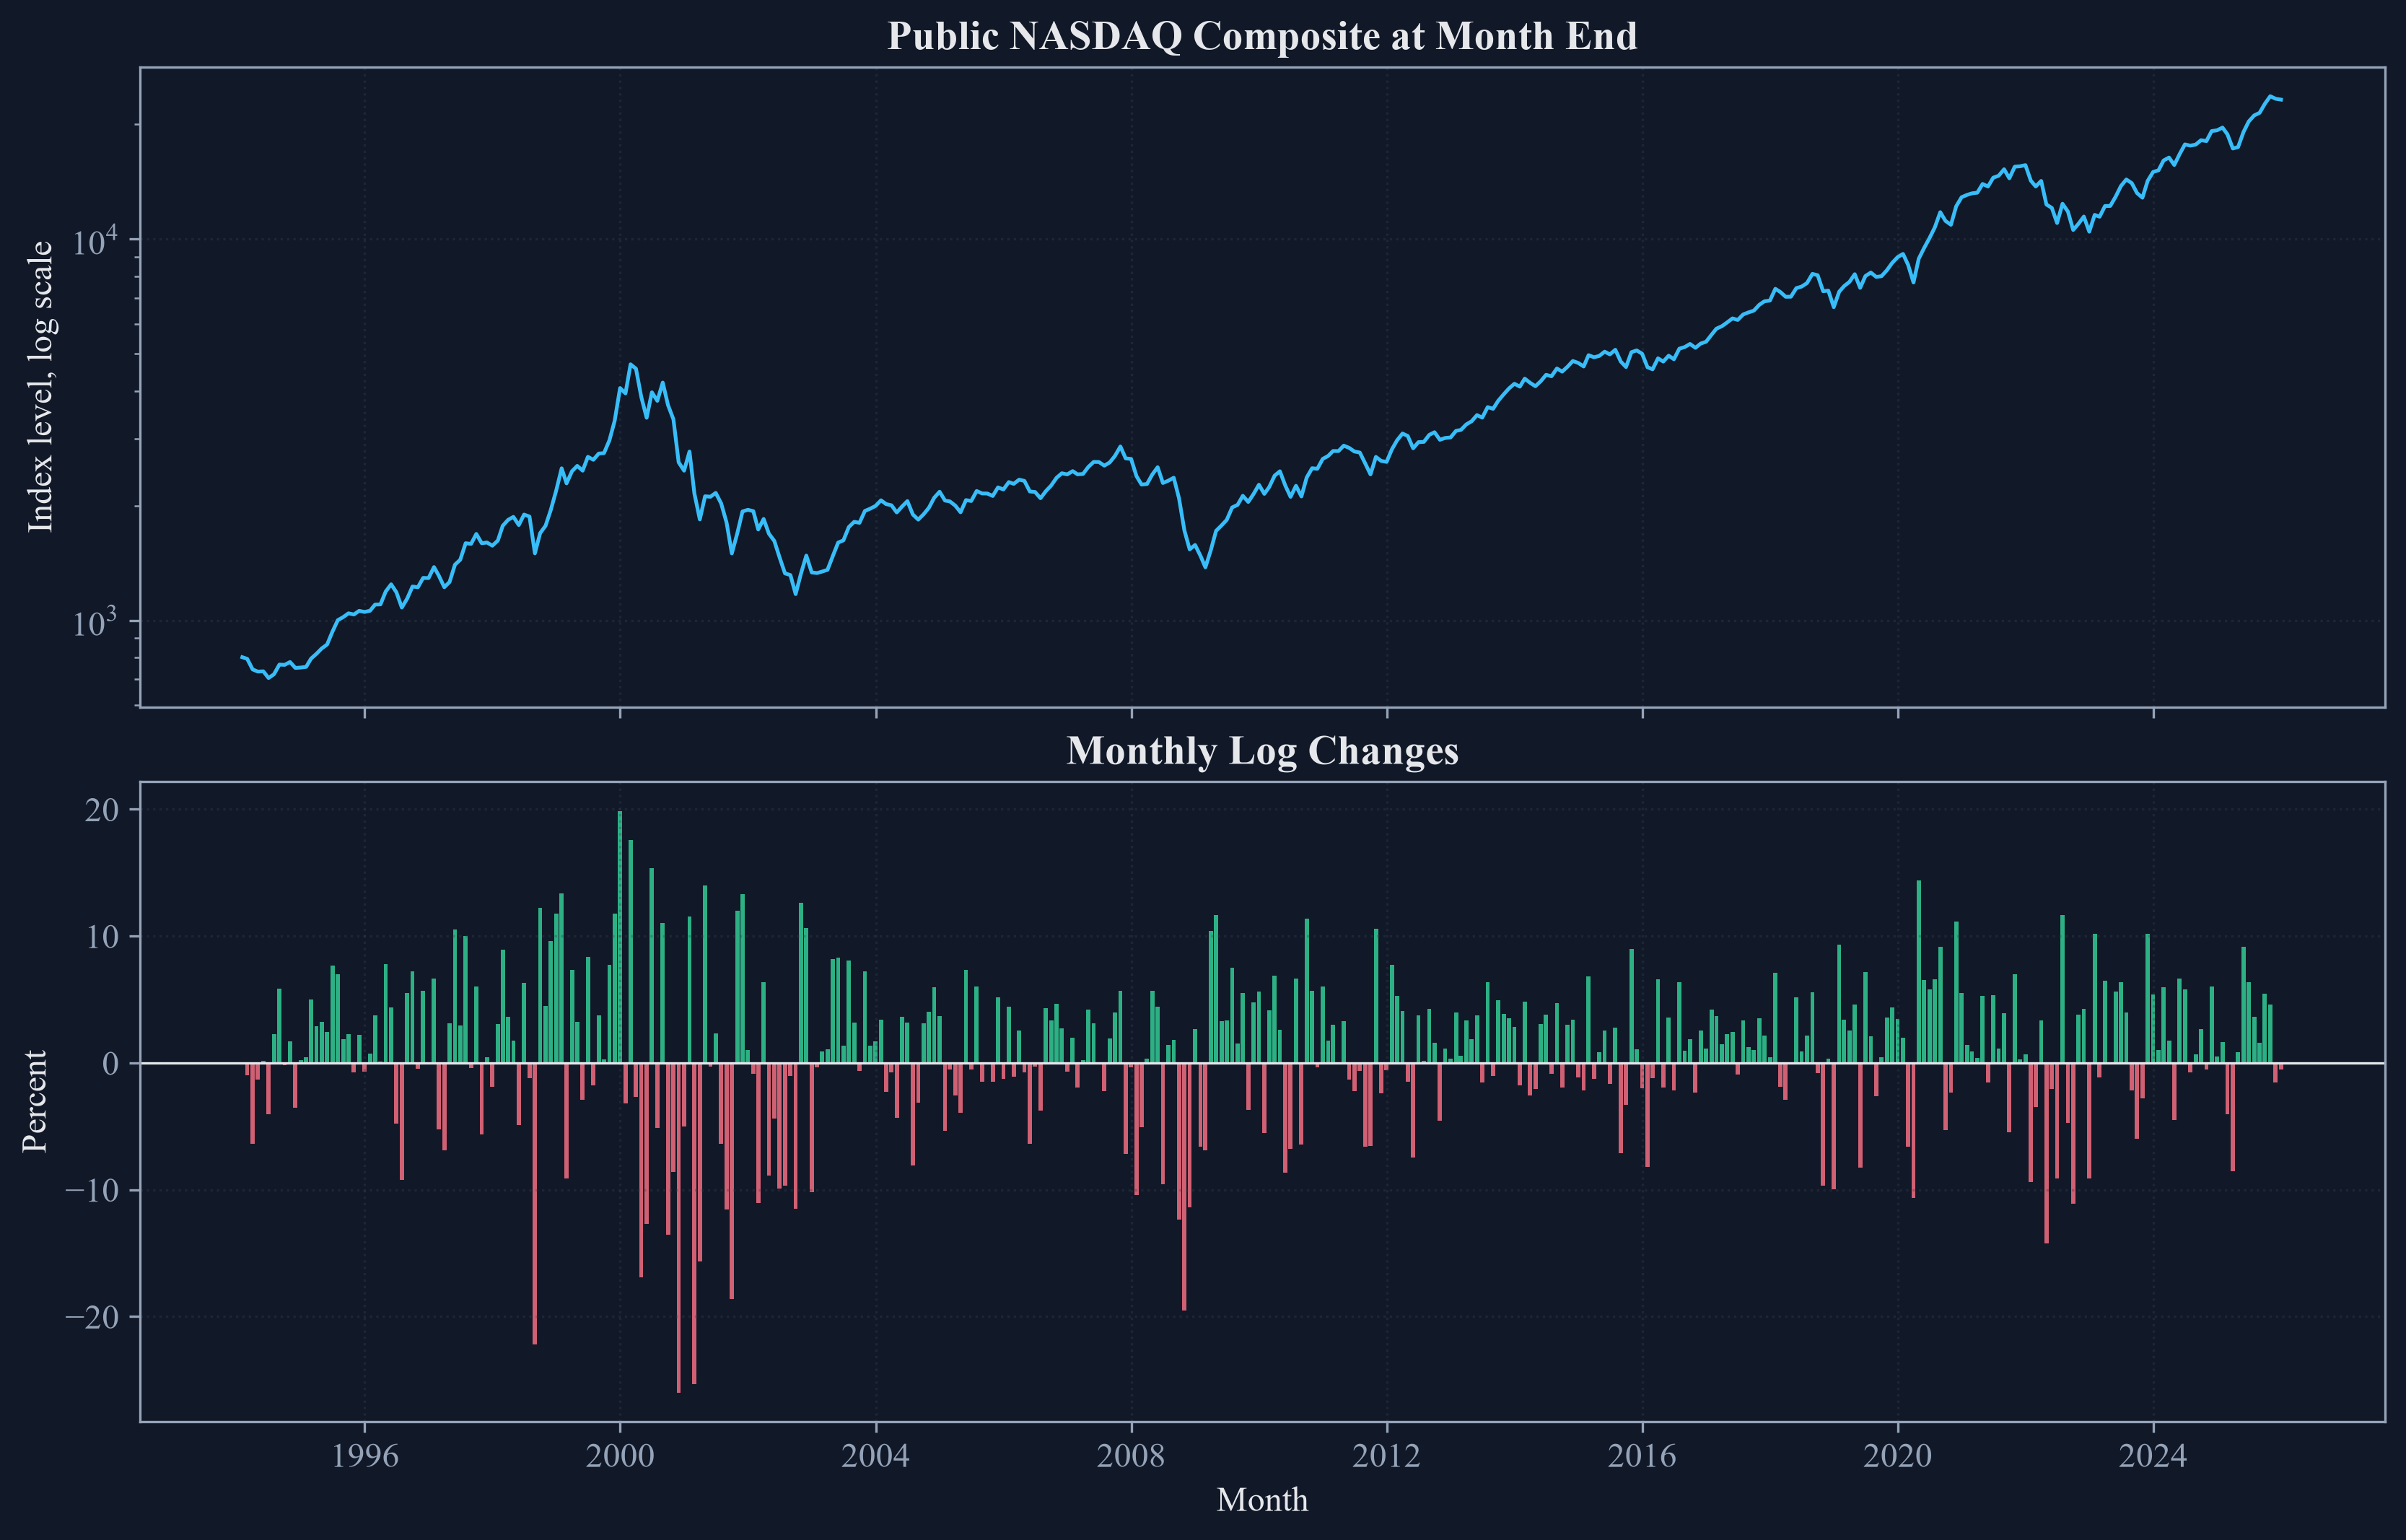

In [2]:
data_provenance = pd.DataFrame({'Field': ['Provider', 'Series', 'Frequency used', 'First month', 'Last month', 'Daily rows', 'Missing daily values', 'Monthly observations', 'Retrieved'], 'Value': ['Federal Reserve Bank of St. Louis', 'NASDAQ Composite, NASDAQCOM', 'Month end', str(monthly_price.index.min().date()), str(monthly_price.index.max().date()), f'{len(raw):,}', f"{raw['NASDAQCOM'].isna().sum():,}", f'{len(monthly_price):,}', '2026-09-26']})
save_table(data_provenance, 'data_provenance', 'Fixed public observations used in Chapter 11.', 'tab:chapter11-data-provenance', fit=True)
display(data_provenance)
figure, axes = plt.subplots(2, 1, figsize=(11.0, 7.0), sharex=True, constrained_layout=True)
axes[0].plot(monthly_price.index, monthly_price, color=palette['cyan'], linewidth=1.25)
axes[0].set_yscale('log')
axes[0].set_title('Public NASDAQ Composite at Month End')
axes[0].set_ylabel('Index level, log scale')
axes[0].grid(alpha=0.35)
axes[1].bar(monthly_return.index, 100 * monthly_return, width=24, color=np.where(monthly_return >= 0, palette['green'], palette['rose']), alpha=0.82)
axes[1].axhline(0, color=palette['text'], linewidth=0.8)
axes[1].set_title('Monthly Log Changes')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Percent')
axes[1].grid(alpha=0.35)
locator = mdates.AutoDateLocator(minticks=6, maxticks=10)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
figure.savefig(FIGURES / 'public_nasdaq_monthly.png', bbox_inches='tight', dpi=300)
figure.savefig(FIGURES / 'public_nasdaq_monthly.pdf', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'public_nasdaq_monthly.png')))
plt.close(figure)


## The Right-Tailed Statistic

Ordinary least squares estimates the regression, and the ADF value measures the lagged-level estimate in standard-error units:

$$
\widehat\theta=(X^{\mathsf T}X)^{-1}X^{\mathsf T}d,
\qquad
\widehat V(\widehat\theta)
=\widehat\sigma_{\varepsilon}^{2}(X^{\mathsf T}X)^{-1},
\qquad
\operatorname{ADF}=\frac{\widehat\beta}{\sqrt{\widehat V(\widehat\theta)_{\beta\beta}}}.
$$

Here, $X$ is the regression matrix; $d$ is the vector of first differences; $\widehat\theta$ contains all estimated coefficients. $\widehat\beta$ is the estimated lagged-level coefficient; $\widehat\sigma_{\varepsilon}^{2}$ is residual variance; $\widehat V$ is the coefficient covariance matrix. $\mathsf T$ denotes transpose; $\widehat V(\widehat\theta)_{\beta\beta}$ is the variance assigned to $\widehat\beta$; $\operatorname{ADF}$ is the right-tailed test statistic.

In [3]:
dependent, regressors = prepare_data(log_price, constant="c", lags=0)
beta_mean, beta_variance = compute_beta(dependent.to_numpy(), regressors.to_numpy())
manual_beta = np.linalg.solve(regressors.to_numpy().T @ regressors.to_numpy(), regressors.to_numpy().T @ dependent.to_numpy())
standard_errors = np.sqrt(np.diag(beta_variance))
coefficient_names = regressors.columns.tolist()
regression_audit = pd.DataFrame({
    "Term": coefficient_names,
    "Estimate": beta_mean.ravel(),
    "Standard error": standard_errors,
    "Statistic": beta_mean.ravel() / standard_errors,
    "Independent estimate": manual_beta.ravel(),
    "Absolute difference": np.abs(beta_mean.ravel() - manual_beta.ravel()),
})
save_table(regression_audit, "adf_regression_audit", "Full-sample ADF regression and an independent coefficient check.", "tab:chapter11-adf-regression-audit", fit=True)
display(regression_audit.round(8))

,Term,Estimate,Standard error,Statistic,Independent estimate,Absolute difference
0,level_l1,-0.000159,0.003736,-0.042471,-0.000159,0
1,constant,0.010089,0.030627,0.329402,0.010089,0


## Expanding Windows

The minimum window grows with the sample, and SADF keeps the largest right-tailed statistic from windows anchored at the first observation:

$$
r_0=0.01+\frac{1.8}{\sqrt{T}},
\qquad
n_0=\max\!\left\{3,\operatorname{round}(r_0T)\right\},
\qquad
\operatorname{SADF}(r_0)=\sup_{r_2\in[r_0,1]}\operatorname{ADF}_{0}^{r_2}.
$$

Here, $T$ is the total number of observations; $r_0$ is the minimum window as a sample fraction; $n_0$ is its observation count. $r_2$ is a window endpoint as a sample fraction; $\operatorname{ADF}_{0}^{r_2}$ uses observations from the sample origin through $r_2.$ $\sup$ denotes the largest value over admissible endpoints; $\operatorname{SADF}(r_0)$ is that largest origin-anchored statistic.

,Quantity,Value
0,Monthly observations,384
1,Minimum window,39
2,First valid endpoint,1997-04-30
3,Final ADF,-0.042471
4,Largest ADF,1.817969
5,Endpoint of largest ADF,2000-02-29
6,Positive-statistic share,0.113043


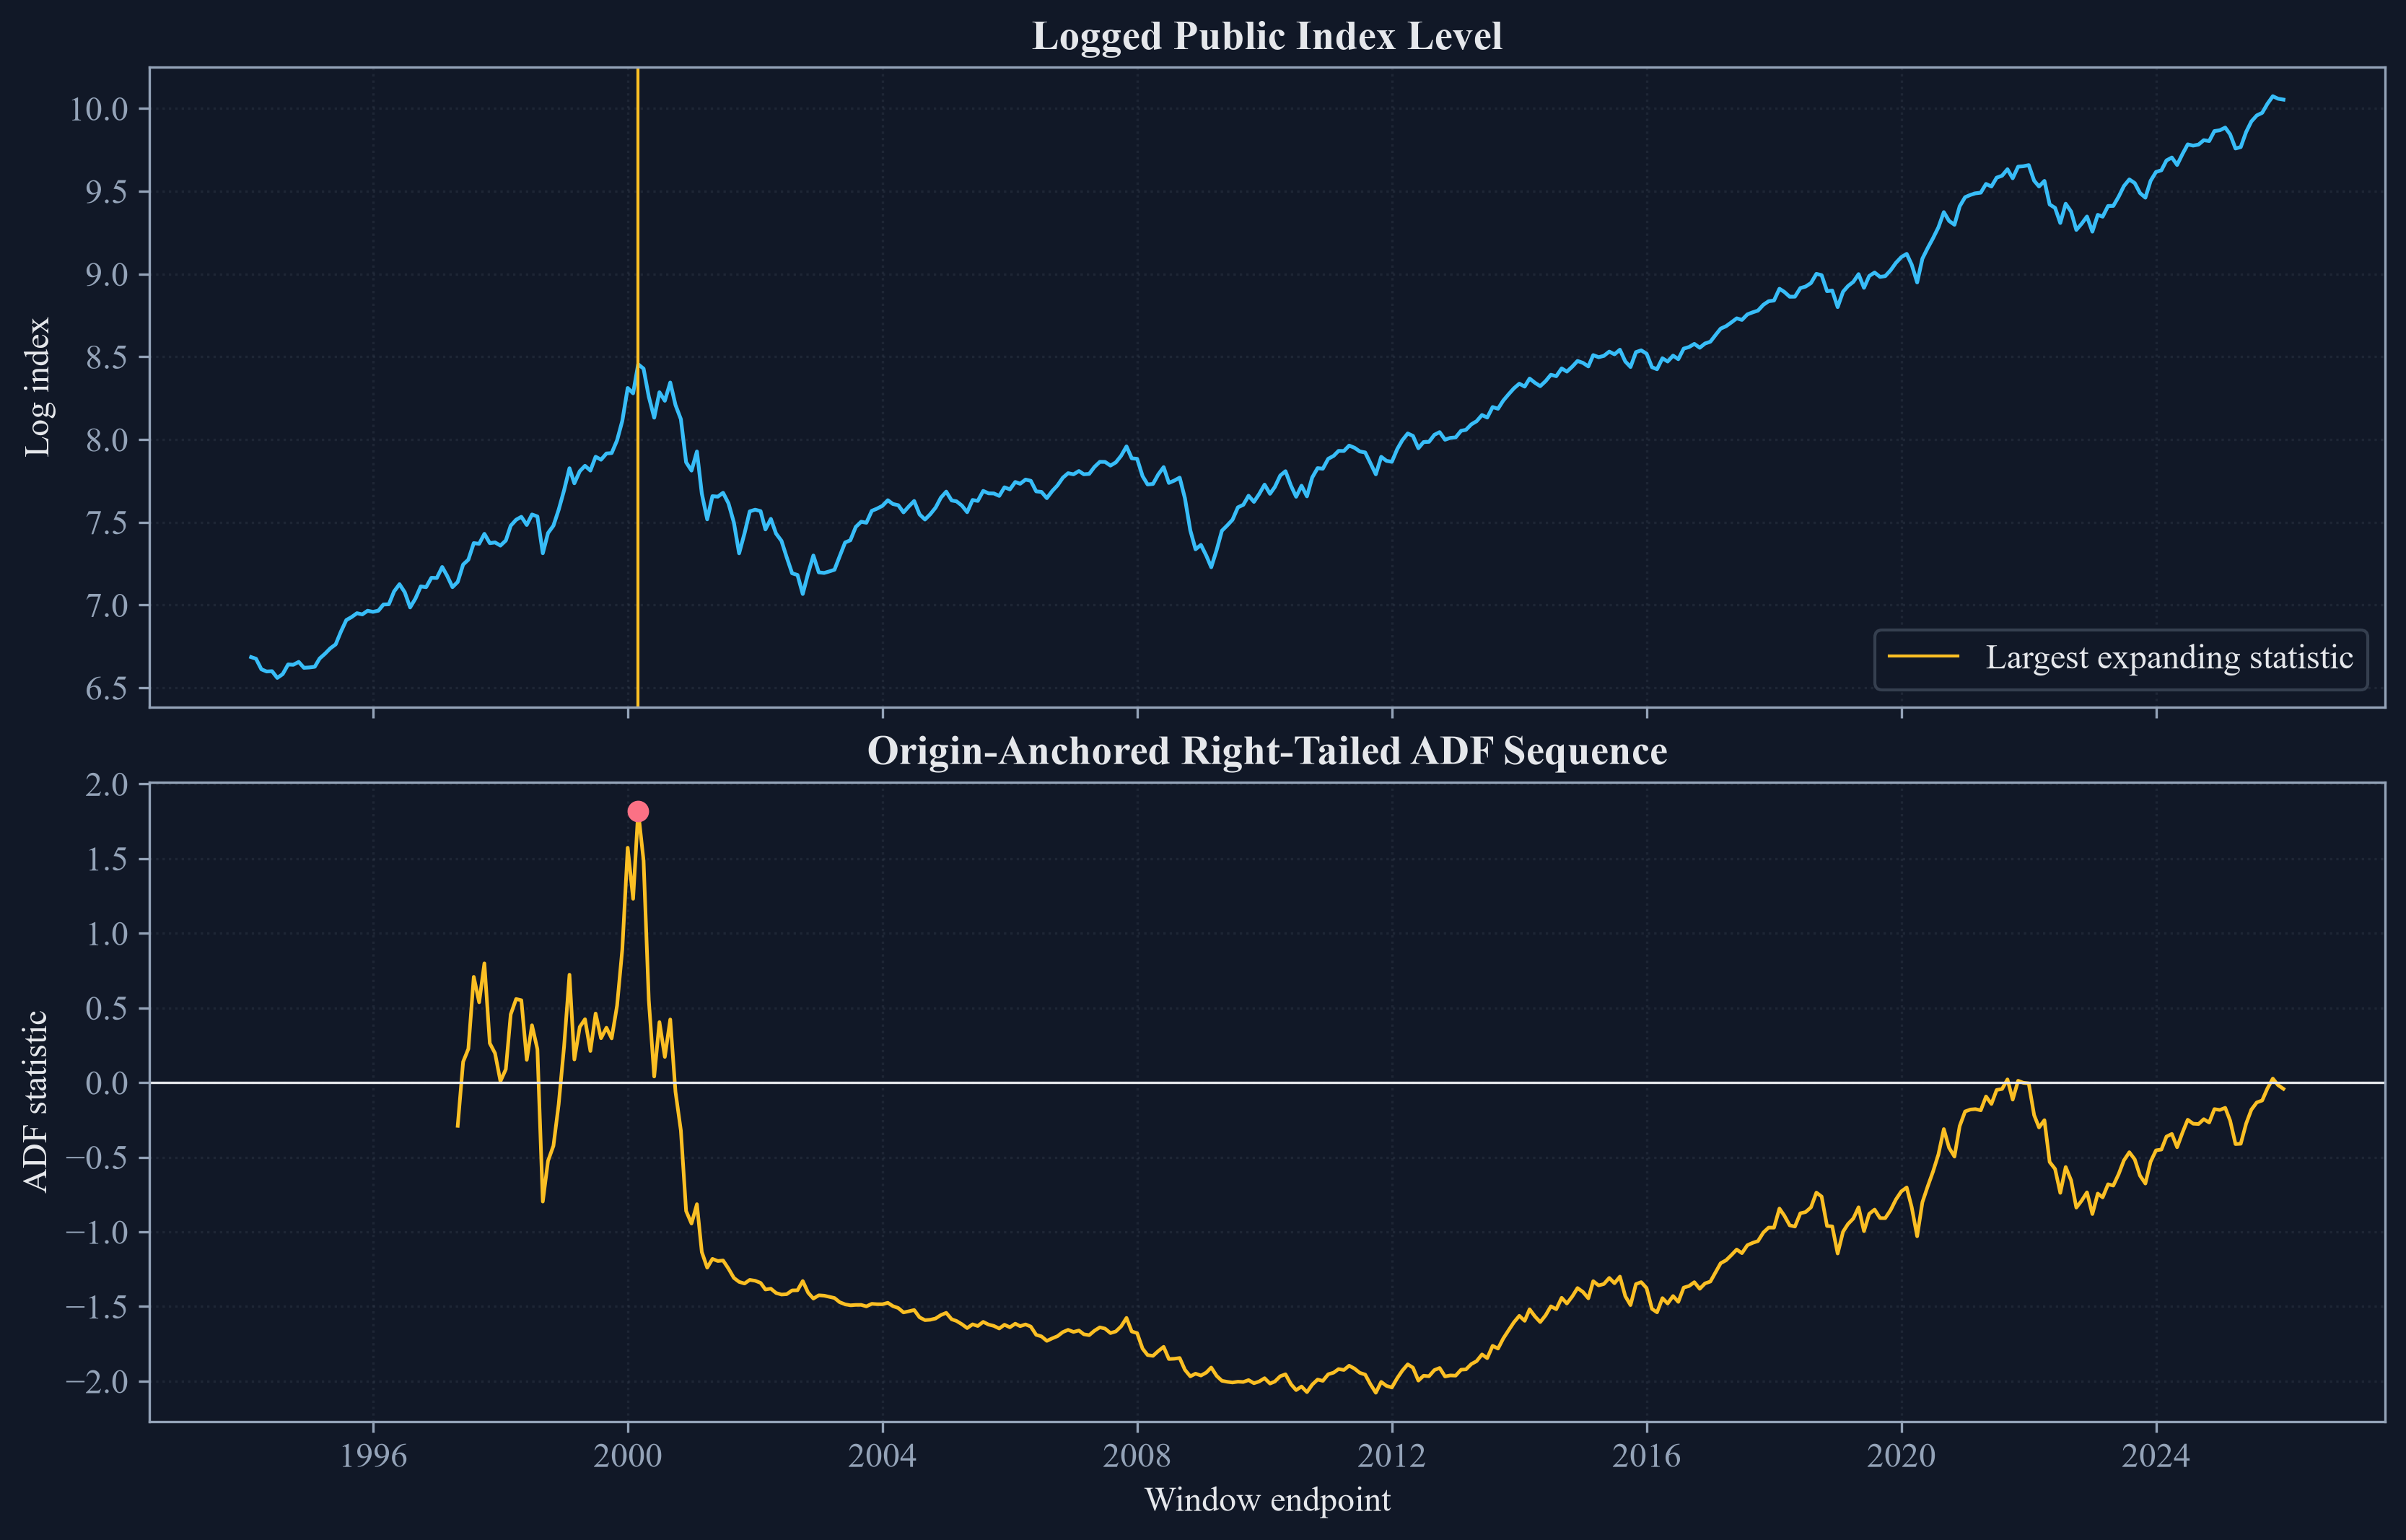

In [4]:
sample_length = len(log_price)
min_window = psy_minimum_window(sample_length)
expanding_adf = get_expanding_window_adf(log_price, min_window, "c", 0)
sadf_sequence = get_sadf_sequence(log_price, min_window, "c", 0)
maximum_date = sadf_sequence.idxmax()
expanding_summary = pd.DataFrame({
    "Quantity": ["Monthly observations", "Minimum window", "First valid endpoint", "Final ADF", "Largest ADF", "Endpoint of largest ADF", "Positive-statistic share"],
    "Value": [f"{sample_length}", f"{min_window}", str(sadf_sequence.index.min().date()), f"{sadf_sequence.iloc[-1]:.6f}", f"{sadf_sequence.max():.6f}", str(maximum_date.date()), f"{sadf_sequence.gt(0).mean():.6f}"],
})
save_table(expanding_summary, "expanding_adf_summary", "Summary of the origin-anchored expanding ADF sequence.", "tab:chapter11-expanding-adf-summary", fit=False)
display(expanding_summary)

figure, axes = plt.subplots(2, 1, figsize=(11.0, 7.0), sharex=True, constrained_layout=True)
axes[0].plot(log_price.index, log_price, color=palette["cyan"], linewidth=1.25)
axes[0].axvline(maximum_date, color=palette["amber"], linewidth=1.0, label="Largest expanding statistic")
axes[0].set_title("Logged Public Index Level")
axes[0].set_ylabel("Log index")
axes[0].legend()
axes[0].grid(alpha=0.35)
axes[1].plot(sadf_sequence.index, sadf_sequence, color=palette["amber"], linewidth=1.2)
axes[1].axhline(0, color=palette["text"], linewidth=0.8)
axes[1].scatter([maximum_date], [sadf_sequence.max()], color=palette["rose"], s=38, zorder=3)
axes[1].set_title("Origin-Anchored Right-Tailed ADF Sequence")
axes[1].set_xlabel("Window endpoint")
axes[1].set_ylabel("ADF statistic")
axes[1].grid(alpha=0.35)
locator = mdates.AutoDateLocator(minticks=6, maxticks=10)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
figure.savefig(FIGURES / "expanding_adf_sequence.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "expanding_adf_sequence.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "expanding_adf_sequence.png")))
plt.close(figure)

## Tests

In [5]:
assert raw.shape == (8348, 2)
assert raw['NASDAQCOM'].isna().sum() == 293
assert daily_price.index.min() == pd.Timestamp('1994-01-03')
assert daily_price.index.max() == pd.Timestamp('2025-12-31')
assert len(monthly_price) == 384
assert monthly_price.index.min() == pd.Timestamp('1994-01-31')
assert monthly_price.index.max() == pd.Timestamp('2025-12-31')
assert monthly_price.gt(0).all()
assert monthly_price.index.is_monotonic_increasing
assert monthly_price.index.is_unique
assert len(monthly_return) == 383
assert min_window == 39
assert dependent.shape == (383, 1)
assert regressors.shape == (383, 2)
assert coefficient_names == ['level_l1', 'constant']
assert np.allclose(beta_mean, manual_beta, atol=1e-12, rtol=0)
assert np.isfinite(beta_variance).all()
assert np.all(np.diag(beta_variance) > 0)
assert len(expanding_adf) == len(sadf_sequence)
assert expanding_adf.index.equals(sadf_sequence.index)
assert np.allclose(expanding_adf, sadf_sequence, atol=1e-09, rtol=0)
assert np.isclose(sadf_sequence.max(), 1.8179690572971872, atol=1e-10)
assert maximum_date == pd.Timestamp('2000-02-29')
assert (FIGURES / 'public_nasdaq_monthly.pdf').is_file()
assert (FIGURES / 'expanding_adf_sequence.pdf').is_file()
assert (TABLES / 'data_provenance.tex').is_file()
assert (TABLES / 'adf_regression_audit.tex').is_file()
assert (TABLES / 'expanding_adf_summary.tex').is_file()
